In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from datetime import datetime

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))




TensorFlow: 2.21.0
GPU devices: []


In [2]:
# CHANGE THIS PATH TO YOUR ACTUAL DATASET DIRECTORY
DATASET_DIR = Path(r"E:\SEM5\ERA\ERA_Project\Brain_Tumor\data")

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

OUTPUT_DIR = Path("outputs/notebook_02")
MODEL_DIR = OUTPUT_DIR / "models"
RESULTS_DIR = OUTPUT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

INITIAL_EPOCHS = 8
FINE_TUNE_EPOCHS = 10

NUM_CLASSES = 4

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

BEST_MODEL_PATH = MODEL_DIR / "resnet50_baseline_best.keras"

print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)
print("Output directory:", OUTPUT_DIR)

assert TRAIN_DIR.exists(), f"Training directory not found: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Testing directory not found: {TEST_DIR}"



Training directory: E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Training
Testing directory: E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testing
Output directory: outputs\notebook_02


In [3]:
os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic operations enabled.")
except Exception as e:
    print("Could not enable full determinism:", e)

    

Deterministic operations enabled.


In [4]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    shuffle=True
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    shuffle=False
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Classes:", train_ds_raw.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds_raw).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds_raw).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds_raw).numpy())

assert train_ds_raw.class_names == CLASS_NAMES
assert val_ds_raw.class_names == CLASS_NAMES
assert test_ds_raw.class_names == CLASS_NAMES



Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training batches: 140
Validation batches: 35
Testing batches: 50


In [5]:
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10)
    ],
    name="data_augmentation"
)


def preprocess_training(image, label):
    image = tf.cast(image, tf.float32)

    # Apply augmentation only during training
    image = data_augmentation(image, training=True)

    # ResNet50 ImageNet preprocessing
    image = preprocess_input(image)

    return image, label


def preprocess_evaluation(image, label):
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)

    return image, label


train_ds = (
    train_ds_raw
    .map(preprocess_training, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds_raw
    .map(preprocess_evaluation, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds_raw
    .map(preprocess_evaluation, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

print("Preprocessing completed.")



Preprocessing completed.


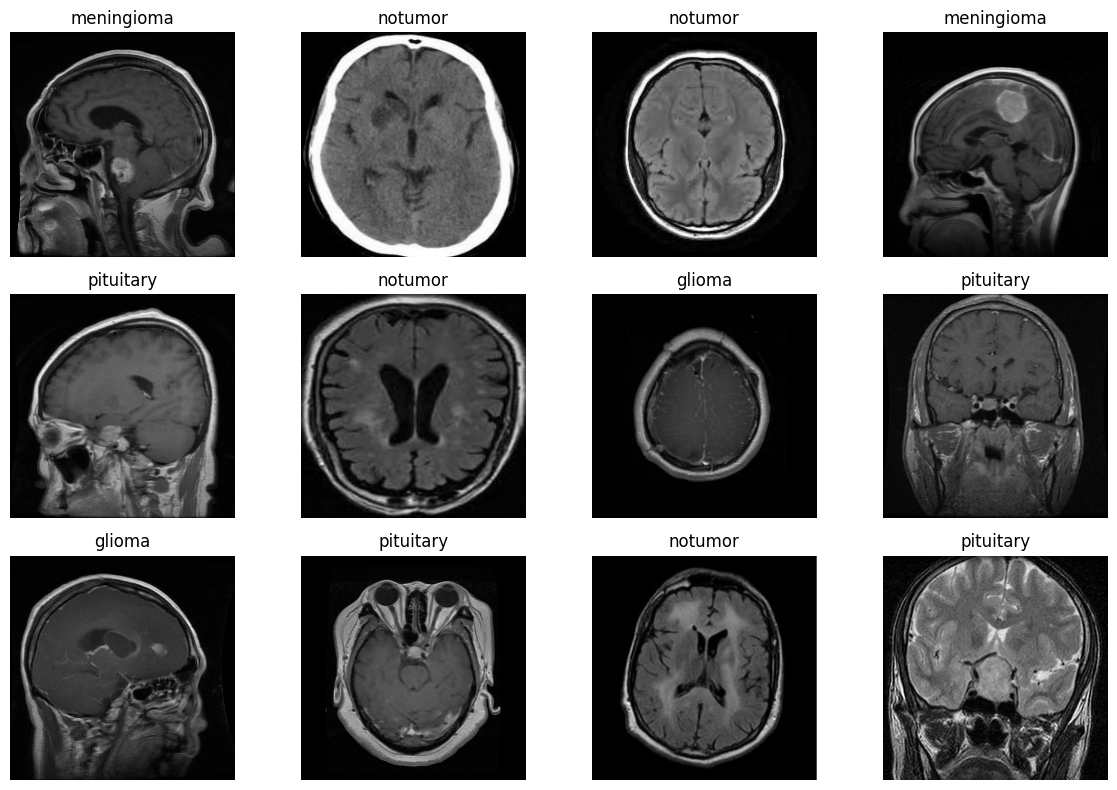

In [6]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds_raw.take(1):

    for i in range(min(12, len(images))):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = labels[i].numpy()
        plt.title(CLASS_NAMES[label_index])

        plt.axis("off")

plt.tight_layout()
plt.show()



In [7]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

# Input images are already preprocessed by the dataset pipeline
x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_Baseline"
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()



Model: "ResNet50_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 529,668 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [8]:
callbacks_initial = [

    keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_initial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks_initial
)



Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7664 - loss: 0.7766
Epoch 1: val_loss improved from None to 0.15844, saving model to outputs\notebook_02\models\resnet50_baseline_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.8266 - loss: 0.5657 - val_accuracy: 0.9357 - val_loss: 0.1584 - learning_rate: 0.0010
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8879 - loss: 0.3499
Epoch 2: val_loss did not improve from 0.15844
140/140 ━━━━━━━━━━━━━━━━━━━━ 236s 2s/step - accuracy: 0.8891 - loss: 0.3472 - val_accuracy: 0.9357 - val_loss: 0.1671 - learning_rate: 0.0010
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9135 - loss: 0.2362
Epoch 3: val_loss improved from 0.15844 to 0.07037, saving model to outputs\notebook_02\models\resnet50_baseline_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 235s 2s/step - accuracy: 0.9167 - loss: 0.2282 - val_accuracy: 0.9821 - val_loss: 0.0704 - learning_rate: 0.0010
Epoch 4/8
140/140 ━━━━━━━━━━━━

In [9]:
base_model.trainable = True

# Freeze all layers except the final 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total base model layers:", len(base_model.layers))
print("Trainable base model layers:",
      sum(layer.trainable for layer in base_model.layers))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_finetune = [

    keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks_finetune
)



Total base model layers: 175
Trainable base model layers: 21
Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9547 - loss: 0.1255
Epoch 1: val_loss improved from None to 0.02133, saving model to outputs\notebook_02\models\resnet50_baseline_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 293s 2s/step - accuracy: 0.9587 - loss: 0.1137 - val_accuracy: 0.9964 - val_loss: 0.0213 - learning_rate: 1.0000e-05
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9631 - loss: 0.1102
Epoch 2: val_loss improved from 0.02133 to 0.01671, saving model to outputs\notebook_02\models\resnet50_baseline_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 285s 2s/step - accuracy: 0.9681 - loss: 0.0920 - val_accuracy: 0.9946 - val_loss: 0.0167 - learning_rate: 1.0000e-05
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9726 - loss: 0.0743
Epoch 3: val_loss improved from 0.01671 to 0.01008, saving model to outputs\notebook_02\models\resnet50_baseline_best.keras
140/140 ━━━━━━━━━━━━━━━

In [10]:
def combine_histories(history1, history2):

    combined = {}

    for key in history1.history:

        combined[key] = (
            history1.history[key] +
            history2.history[key]
        )

    return combined


combined_history = combine_histories(
    history_initial,
    history_finetune
)

history_df = pd.DataFrame(combined_history)

history_df.to_csv(
    RESULTS_DIR / "training_history.csv",
    index=False
)

history_df.head()



,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.826563,0.565739,0.935714,0.158443,0.001
1,0.889063,0.347156,0.935714,0.167088,0.001
2,0.916741,0.228196,0.982143,0.070372,0.001
3,0.925000,0.205100,0.990179,0.032895,0.001
4,0.943750,0.151492,0.997321,0.014056,0.001


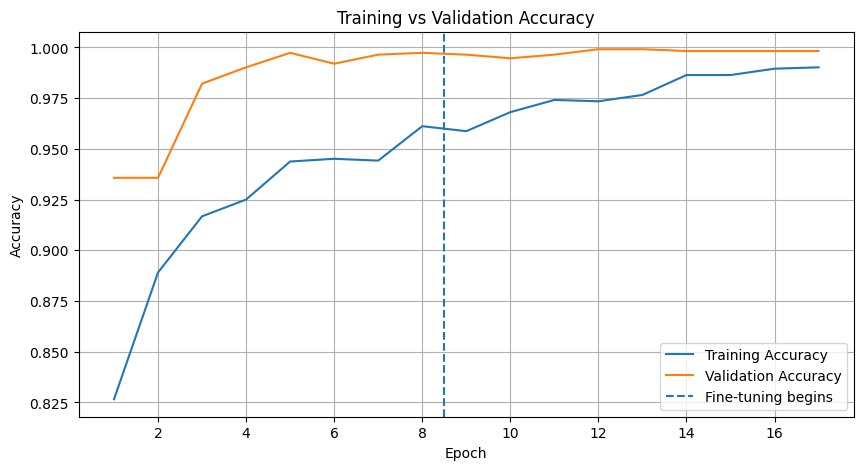

In [11]:
epochs = range(1, len(combined_history["accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    combined_history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    combined_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=INITIAL_EPOCHS + 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULTS_DIR / "accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



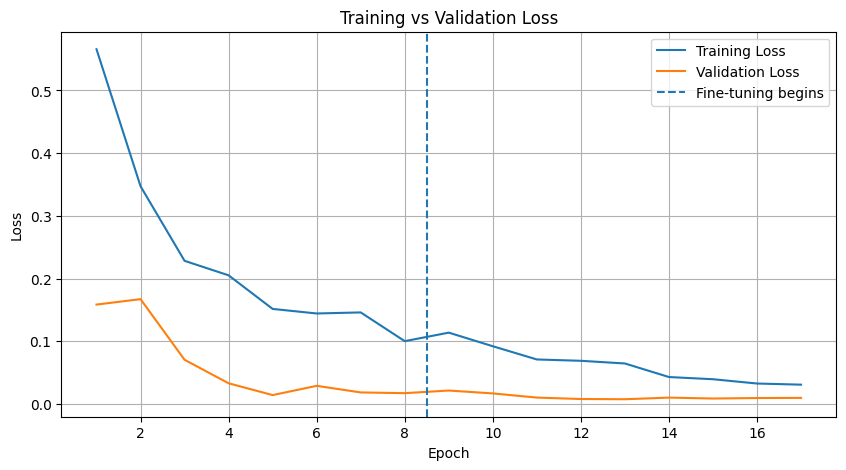

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    combined_history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    combined_history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=INITIAL_EPOCHS + 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULTS_DIR / "loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [13]:
best_model = keras.models.load_model(
    BEST_MODEL_PATH
)

print("Best model loaded successfully.")




Best model loaded successfully.


In [14]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nTEST RESULTS")
print("-" * 40)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")




50/50 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.9119 - loss: 0.5228

TEST RESULTS
----------------------------------------
Test Loss     : 0.5228
Test Accuracy : 91.19%


In [15]:
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Prediction probabilities shape:", y_prob.shape)



50/50 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step
Actual labels shape: (1600,)
Predicted labels shape: (1600,)
Prediction probabilities shape: (1600, 4)


In [16]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

metrics = {
    "accuracy": float(accuracy),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(f1),
    "test_loss": float(test_loss)
}

print("FINAL METRICS")
print("-" * 40)

for key, value in metrics.items():
    print(f"{key}: {value:.4f}")

with open(RESULTS_DIR / "evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

    

FINAL METRICS
----------------------------------------
accuracy: 0.9119
precision_macro: 0.9134
recall_macro: 0.9119
f1_macro: 0.9100
test_loss: 0.5228


In [17]:
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df)

report_df.to_csv(
    RESULTS_DIR / "classification_report.csv"
)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)



,precision,recall,f1-score,support
glioma,0.942598,0.780000,0.853625,400.000000
meningioma,0.854015,0.877500,0.865598,400.000000
notumor,0.956835,0.997500,0.976744,400.000000
pituitary,0.900227,0.992500,0.944114,400.000000
accuracy,0.911875,0.911875,0.911875,0.911875
macro avg,0.913419,0.911875,0.910020,1600.000000
weighted avg,0.913419,0.911875,0.910020,1600.000000


              precision    recall  f1-score   support

      glioma       0.94      0.78      0.85       400
  meningioma       0.85      0.88      0.87       400
     notumor       0.96      1.00      0.98       400
   pituitary       0.90      0.99      0.94       400

    accuracy                           0.91      1600
   macro avg       0.91      0.91      0.91      1600
weighted avg       0.91      0.91      0.91      1600



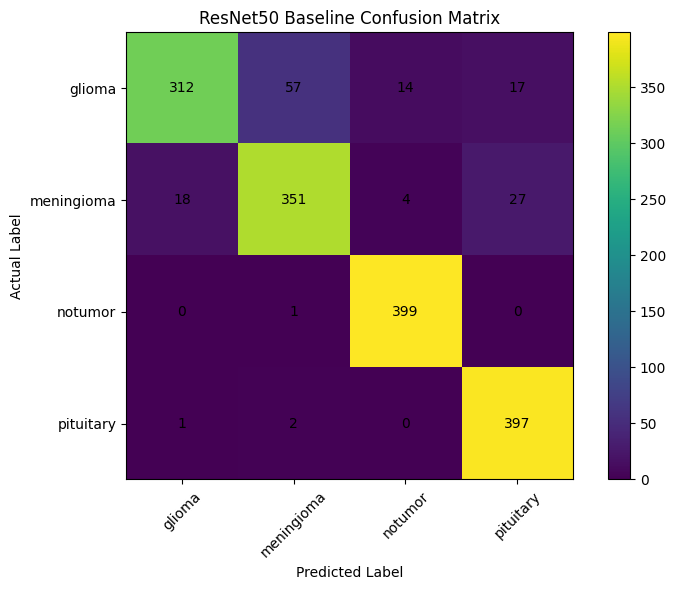

In [18]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(NUM_CLASSES)
)

plt.figure(figsize=(8, 6))

plt.imshow(cm, interpolation="nearest")

plt.title("ResNet50 Baseline Confusion Matrix")
plt.colorbar()

ticks = np.arange(NUM_CLASSES)

plt.xticks(ticks, CLASS_NAMES, rotation=45)
plt.yticks(ticks, CLASS_NAMES)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [19]:
confidence = np.max(y_prob, axis=1)

correct_predictions = (y_true == y_pred)

confidence_df = pd.DataFrame({
    "actual_class": [CLASS_NAMES[i] for i in y_true],
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "confidence": confidence,
    "correct": correct_predictions
})

print("Average confidence:", confidence.mean())

print(
    "\nAverage confidence for correct predictions:",
    confidence_df.loc[
        confidence_df["correct"], "confidence"
    ].mean()
)

print(
    "\nAverage confidence for incorrect predictions:",
    confidence_df.loc[
        ~confidence_df["correct"], "confidence"
    ].mean()
)

confidence_df.to_csv(
    RESULTS_DIR / "prediction_confidence.csv",
    index=False
)

display(confidence_df.head(10))



Average confidence: 0.96414113

Average confidence for correct predictions: 0.9780126

Average confidence for incorrect predictions: 0.8206063


,actual_class,predicted_class,confidence,correct
0,glioma,pituitary,0.902704,False
1,glioma,glioma,1.000000,True
2,glioma,glioma,1.000000,True
3,glioma,pituitary,0.880811,False
4,glioma,glioma,0.910698,True
5,glioma,glioma,0.971162,True
6,glioma,glioma,0.786094,True
7,glioma,glioma,0.999999,True
8,glioma,meningioma,0.993972,False
9,glioma,glioma,0.999744,True


In [20]:
class_results = []

for i, class_name in enumerate(CLASS_NAMES):

    class_mask = (y_true == i)

    total = int(class_mask.sum())

    correct = int(
        np.sum((y_true == i) & (y_pred == i))
    )

    class_results.append({
        "Class": class_name,
        "Total Images": total,
        "Correct Predictions": correct,
        "Incorrect Predictions": total - correct,
        "Recall": correct / total if total else 0
    })

class_results_df = pd.DataFrame(class_results)

display(class_results_df)

class_results_df.to_csv(
    RESULTS_DIR / "class_wise_results.csv",
    index=False
)



,Class,Total Images,Correct Predictions,Incorrect Predictions,Recall
0,glioma,400,312,88,0.7800
1,meningioma,400,351,49,0.8775
2,notumor,400,399,1,0.9975
3,pituitary,400,397,3,0.9925


In [21]:
FINAL_MODEL_PATH = MODEL_DIR / "resnet50_baseline_final.keras"

best_model.save(FINAL_MODEL_PATH)

print("Model saved at:", FINAL_MODEL_PATH)



Model saved at: outputs\notebook_02\models\resnet50_baseline_final.keras


In [22]:
experiment_config = {
    "experiment": "Notebook 02 - ResNet50 Baseline",
    "date": datetime.now().isoformat(),
    "architecture": "ResNet50",
    "pretrained_weights": "ImageNet",
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "validation_split": 0.20,
    "initial_epochs": INITIAL_EPOCHS,
    "fine_tune_epochs": FINE_TUNE_EPOCHS,
    "fine_tune_layers": 30,
    "initial_learning_rate": 0.001,
    "fine_tune_learning_rate": 0.00001,
    "classes": CLASS_NAMES,
    "augmentation": [
        "horizontal_flip",
        "rotation",
        "zoom",
        "contrast"
    ],
    "metrics": metrics
}

with open(
    RESULTS_DIR / "experiment_config.json",
    "w"
) as f:
    json.dump(experiment_config, f, indent=4)

print("Experiment configuration saved.")

Experiment configuration saved.
